# 3 · Your own planet

**What you will learn:** how to describe a planet other than Jupiter — its mass, radius and rotation; how to hand PyToF a density profile directly instead of a barotrope; how atmospheres and density jumps are treated; and how to tune a model to measured gravitational moments.

Notebook 1 started from a barotrope $\rho(P)$ and let PyToF find densities and shape together (`relax_to_barotrope`). There are two more entry points, and the choice depends on what you know about the interior:

| you provide | method | PyToF computes |
|---|---|---|
| $\rho(P)$ | `set_barotrope(f)` + `relax_to_barotrope()` | pressures, densities and shape |
| $\rho(l)$ on the grid | set `X.li`, `X.rhoi` + `relax_to_shape()` | shape (and $J_{2n}$) |
| $\rho(l)$ on the grid, possibly with an atmosphere | `relax_to_density()` | shape and pressures |

In [1]:
import sys
import pathlib
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import trapezoid
from scipy.optimize import brentq

# Optional personal matplotlib style: used if a file mpl_config.py exists in a
# folder above this one, silently ignored otherwise.
for parent in pathlib.Path.cwd().resolve().parents[:4]:
    if (parent / "mpl_config.py").exists():
        sys.path.insert(0, str(parent))
        break
try:
    from mpl_config import apply_mpl_opts

    apply_mpl_opts()
except ImportError:
    pass  # plain matplotlib defaults

from PyToF import ToF
from tutorial_utils import LABELS, profiles

## The physical parameters

| option | meaning | default (Jupiter) |
|---|---|---|
| `M_phys` | mass [kg] | $1.898\times10^{27}$ |
| `R_phys` | `[value in m, kind]` with kind `'equatorial'`, `'mean'` or `'polar'` | `[71492000, 'equatorial']` |
| `R_ref` | reference radius in the *definition* of the $J_{2n}$ [m] | the value in `R_phys` |
| `Period` | rotation period [s] | 9.925 h |
| `P0` | pressure at the outer surface [Pa] | 0 |
| `G` | gravitational constant | $6.67385\times10^{-11}$ |

`R_phys` tells PyToF which radius your outermost level surface corresponds to; it is used to place the planet on the grid and to check consistency. `R_ref` is purely a convention of the *output*: $J_{2n}$ is defined with respect to a reference radius, usually the equatorial radius at the 1 bar level. Changing it rescales the moments by $(R_\mathrm{ref,1}/R_\mathrm{ref,2})^{2n}$ and changes nothing physical. As an example, Neptune with the values of Wang et al. (2023) and Lindal (1992):

In [2]:
neptune = dict(
    G=6.67430e-11,  # CODATA 2022
    M_phys=1.02409e26,  # Jacobson (2009)
    R_ref=25225e3,  # reference radius of the J's, Wang et al. (2023)
    R_phys=[24766e3, "equatorial"],  # radius at 1 bar, Lindal (1992)
    Period=57479,  # Karkoschka (2011)
    P0=1e5,  # 1 bar
)

## A density profile you provide

Suppose you have an interior model as density versus radius — from a table, a formula or another code. PyToF works on a grid of `N` mean radii, **starting at the outer surface and decreasing**; the radius of the grid's outermost point is the radius you give in `R_phys`. A uniform-density test planet (a Maclaurin spheroid, rotating once per day):

In [3]:
N = 1024
radius = 1e6  # m
period = 24 * 3600  # s
radii = radius * np.linspace(1, 1e-3, N)  # outer surface first
densities = 1000 * np.ones(N)  # kg/m^3
mass = -4 * np.pi * trapezoid(densities * radii**2, radii)  # minus: radii decrease

X = ToF(N=N, order=4, M_phys=mass, R_phys=[radius, "mean"], Period=period)

X.li = radii
X.rhoi = densities
# rotational parameter m = omega^2 l_max^3 / (G M), PyToF's measure of rotation:
X.m_rot_calc = (2 * np.pi / period) ** 2 * X.li[0] ** 3 / (X.opts["G"] * mass)

n_iterations = X.relax_to_shape()
X.get_Js_errors()
print("iterations:", n_iterations)
for n in range(1, 4):
    print(f"J_{2 * n} = {X.Js[n]:.5e} +/- {X.Js_errors[n]:.1e}")

iterations: 49
J_2 = 9.54772e-03 +/- 4.9e-08
J_4 = -1.95344e-04 +/- 4.9e-08
J_6 = 5.17427e-06 +/- 4.5e-08


`relax_to_shape()` does not touch your densities; it only finds the shape for them (iterating until the moments change by less than `dJ_tol`). It also checks that the shape is consistent with the radius you declared in `R_phys` and warns if not. A typical mistake: the grid starts at the *mean* radius of the planet, but the declared radius is called *equatorial*, which for a rotating planet is larger:

In [4]:
Y = ToF(N=N, order=4, M_phys=mass, R_phys=[radius, "equatorial"], Period=period)
Y.li, Y.rhoi, Y.m_rot_calc = radii, densities, X.m_rot_calc
Y.relax_to_shape();  # warns

/tmp/ipykernel_16419/2543654295.py:3: PyToFWarning: Your provided equatorial radius is not consistent with the shape of the planet calculated by PyToF! Your value: 1.00000e+06 / PyToF value: 1.00805e+06
  Y.relax_to_shape();  # warns


Density profiles are often given as a function with free parameters. A common pattern is to define the *shape* of the profile and normalize it to the mass, so that mass is conserved by construction:

J_2 = 4.10398e-03 +/- 2.1e-08


Text(0, 0.5, 'density $\\rho$ [g cm$^{-3}$]')

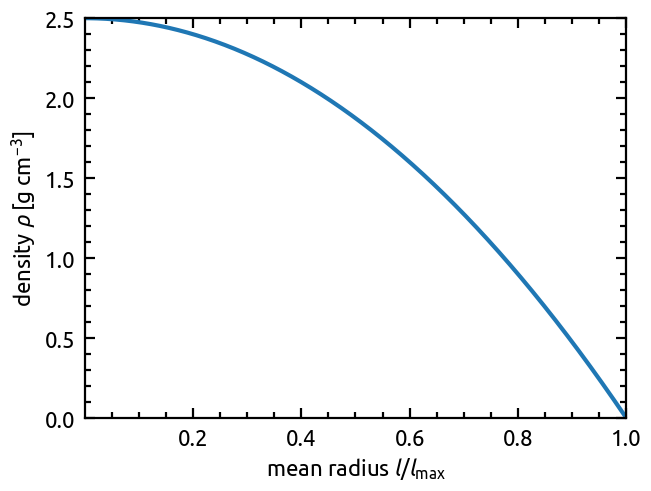

In [5]:
def dens_function(radii, mass, param=None):
    x = radii / np.max(radii)
    densities = 1 - x**2  # shape of the profile
    densities /= -4 * np.pi * trapezoid(densities * radii**2, radii) / mass  # renormalize
    return densities

X = ToF(N=N, order=4, M_phys=mass, R_phys=[radius, "mean"], Period=period)
X.li = radii
X.rhoi = dens_function(radii, mass)
X.m_rot_calc = (2 * np.pi / period) ** 2 * X.li[0] ** 3 / (X.opts["G"] * mass)
X.relax_to_shape()
X.get_Js_errors()
print("J_2 = {:.5e} +/- {:.1e}".format(X.Js[1], X.Js_errors[1]))

p = profiles(X)
fig, ax = plt.subplots(layout="constrained")
ax.plot(p["r"], p["rho"])
ax.set_xlabel(LABELS["r"])
ax.set_ylabel(LABELS["rho"])

## Density jumps

Real planets have composition boundaries, where density jumps. PyToF integrates with Simpson's rule by default, which is more accurate for smooth profiles but cannot handle a jump. When it detects the problem it **switches to the trapezoid rule on its own** and tells you at `verbosity>=1`; the result is then valid but somewhat less accurate (see notebook 5). `X.simpson_in_use` says which rule was used. A planet with a dense core (3000 kg/m³) inside half of its radius:

In [6]:
dens_core = np.where(radii < 0.5 * radius, 3000.0, 1000.0)
mass_core = -4 * np.pi * trapezoid(dens_core * radii**2, radii)

X = ToF(N=N, order=4, M_phys=mass_core, R_phys=[radius, "mean"], Period=period, R_ref=radius, verbosity=1)
X.li, X.rhoi = radii, dens_core
X.m_rot_calc = (2 * np.pi / period) ** 2 * X.li[0] ** 3 / (X.opts["G"] * mass_core)
X.relax_to_shape()
print("Simpson's rule in use:", X.simpson_in_use)

Reverting to the more stable and less accurate trapezoid rule for integration since S_0, itself proportional to the enclosed mass function, has become non-monotonic. Discontinuities in the density gradient due to jumps in density are likely responsible.
Simpson's rule in use: False


The fallback is reset by `X.reset()`, so a new calculation on the same object starts with Simpson's rule again. If you know that your profile has jumps, `use_simpson=False` skips the attempt.

## An atmosphere

The outermost part of a planet is not described well by the interior model: the density profile (or barotrope) of the interior is joined to a separate *atmosphere model* at a given pressure. The atmosphere model is a function `f(l, P, ...)` of the normalized mean radius and the pressure that returns a density; `atmosphere_until` is the pressure [Pa] at which PyToF may switch to the interior model:

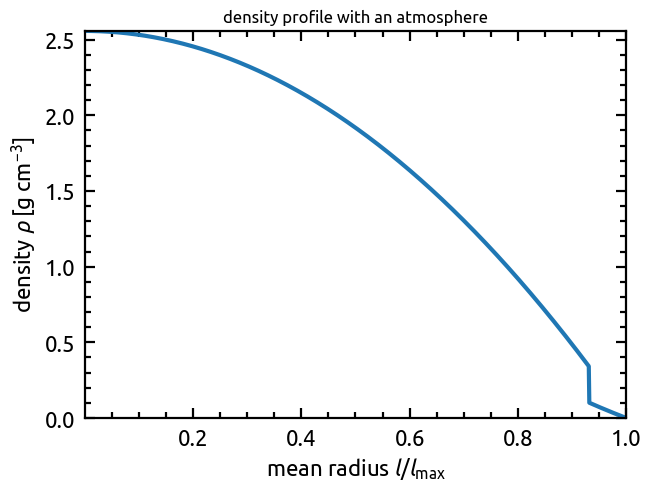

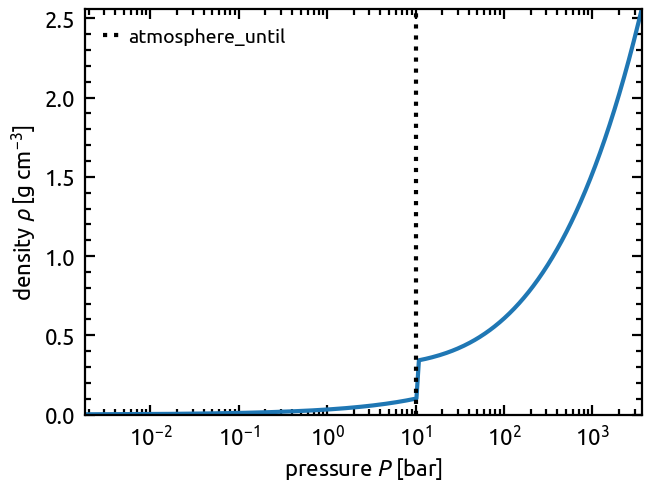

In [7]:
def atmosphere(norm_radii, pressure, K=1e2):
    return (pressure / K) ** (1 / 2)

atm = dict(use_atmosphere=True, atmosphere=atmosphere, atmosphere_until=1e6)  # 10 bar

X = ToF(N=N, order=4, M_phys=mass, R_phys=[radius, "mean"], Period=period, **atm)
X.li, X.rhoi = radii, dens_function(radii, mass)
X.m_rot_calc = (2 * np.pi / period) ** 2 * X.li[0] ** 3 / (X.opts["G"] * mass)

X.relax_to_density()  # densities are given, PyToF finds the shape and the pressures
p = profiles(X)

fig, ax = plt.subplots(layout="constrained")
ax.plot(p["r"], p["rho"])
ax.set_xlabel(LABELS["r"])
ax.set_ylabel(LABELS["rho"])
ax.set_title("density profile with an atmosphere")

fig, ax = plt.subplots(layout="constrained")
ax.plot(p["P"][:-1], p["rho"][:-1])
ax.set_xscale("log")
ax.axvline(1e6 / 1e5, color="k", linestyle=":", label="atmosphere_until")
ax.set_xlabel(LABELS["P"])
ax.set_ylabel(LABELS["rho"])
ax.legend(frameon=False)

At 10 bar the density jumps from the atmosphere model to the interior profile — a density jump, so PyToF uses the trapezoid rule here. The same works with a barotrope instead of a given density profile: set `use_atmosphere`, `atmosphere`, `atmosphere_until` and call `relax_to_barotrope()`.

## Tuning a model to measured moments: a two-layer Neptune

A typical use is to adjust a few parameters until the gravitational moments match the measured ones. Consider Neptune with $J_2 = 3401.655\times10^{-6}$ and $J_4 = -33.294\times10^{-6}$ (Wang et al. 2023). A minimal interior model: a polytrope $\rho = \sqrt{P/K}$ everywhere, but with a denser core, i.e. the density is multiplied by `ratio` above a pressure `P_core`, expressed as a fraction of the central pressure. (A barotrope receives the pressure array and the parameter list set in `baro_param`.)

In [8]:
def barotrope(P, param):
    P_core, ratio = param
    rho = np.sqrt(P)  # K = 1, irrelevant: densities are rescaled to the mass
    return np.where(P / np.max(P) > P_core, ratio * rho, rho)

def neptune_model(ratio, P_core=0.01, order=7, N=512):
    X = ToF(**neptune, N=N, order=order, baro_param=[P_core, ratio])
    X.set_barotrope(barotrope)
    X.relax_to_barotrope()
    return X

for ratio in (1.0, 1.25, 1.5, 2.0):
    X = neptune_model(ratio)
    print(f"ratio = {ratio:4.2f}:  J2 = {X.Js[1] * 1e6:7.1f}e-6   J4 = {X.Js[2] * 1e6:6.2f}e-6   I/(M R^2) = {X.get_NMoI():.4f}")

ratio = 1.00:  J2 =  4312.2e-6   J4 = -50.31e-6   I/(M R^2) = 0.2643


ratio = 1.25:  J2 =  3829.7e-6   J4 = -40.13e-6   I/(M R^2) = 0.2516


ratio = 1.50:  J2 =  3403.1e-6   J4 = -32.11e-6   I/(M R^2) = 0.2397


ratio = 2.00:  J2 =  2668.6e-6   J4 = -20.51e-6   I/(M R^2) = 0.2167


$J_2$ falls monotonically with the core density, so a root finder can tune `ratio` to the measured $J_2$ (each model takes a fraction of a second):

ratio = 1.5013
J2 = 3401.655e-6 (measured 3401.655e-6)
J4 = -32.08e-6 (measured -33.29e-6 +/- 10e-6)


Text(0.5, 1.0, 'two-layer Neptune matching $J_2$')

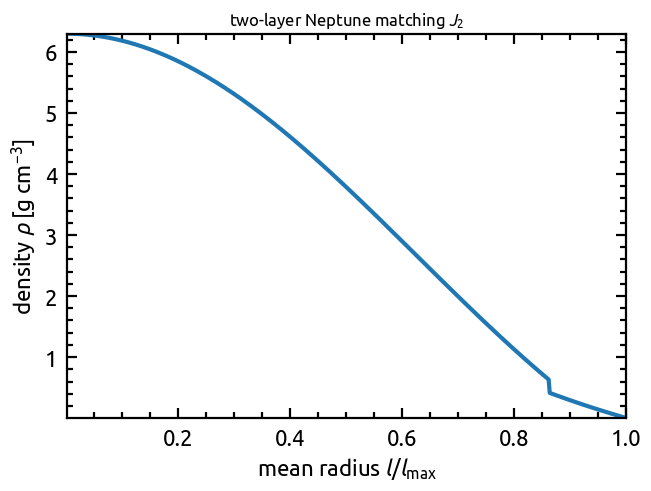

In [9]:
J2_measured, J4_measured, J4_sigma = 3401.655e-6, -33.294e-6, 10.0e-6

ratio_fit = brentq(lambda ratio: neptune_model(ratio).Js[1] - J2_measured, 1.0, 2.0, xtol=1e-6)
X = neptune_model(ratio_fit)
print(f"ratio = {ratio_fit:.4f}")
print(f"J2 = {X.Js[1] * 1e6:.3f}e-6 (measured {J2_measured * 1e6:.3f}e-6)")
print(f"J4 = {X.Js[2] * 1e6:.2f}e-6 (measured {J4_measured * 1e6:.2f}e-6 +/- {J4_sigma * 1e6:.0f}e-6)")

p = profiles(X)
fig, ax = plt.subplots(layout="constrained")
ax.plot(p["r"], p["rho"])
ax.set_xlabel(LABELS["r"])
ax.set_ylabel(LABELS["rho"])
ax.set_title("two-layer Neptune matching $J_2$")

$J_4$ comes out within the measurement uncertainty — one parameter was tuned to one number, the second moment is a prediction. With more free parameters than data, and uncertainties on the data, such a one-dimensional root search turns into a sampling problem. That is done with a Markov chain Monte Carlo sampler on top of PyToF; the separate code collection `PyToF_MCMC` (not part of PyToF) shows one way to do it.

## Takeaways

* Give PyToF mass, radius (`R_phys`), rotation (`Period`) and, if you like, a reference radius for the moments (`R_ref`).
* Three entry points: barotrope → `relax_to_barotrope()`; density profile → set `X.li`, `X.rhoi`, `X.m_rot_calc` → `relax_to_shape()`; density profile with an atmosphere or pressures wanted → `relax_to_density()`.
* Grids run from the outer surface inward. Density jumps are fine; PyToF falls back to the trapezoid rule by itself.
* A PyToF model is cheap enough to sit inside a root finder or an optimizer.

Next: [4 · beyond the Js](04_beyond_the_Js.ipynb).